# Pathological Loss Landscapes: Examples and Fixes

Two classic ways a loss surface makes training hard, each with a runnable demo and a fix:

1. **Ill-conditioning (narrow valley)**: curvature differs hugely between directions, so no single learning rate works. Fixes: momentum, Adam, preconditioning, input normalization.
2. **Saturation plateaus (vanishing gradients)**: the loss is high but the gradient is ~0. Fixes: cross-entropy loss, ReLU-type activations, proper initialization.

Only NumPy and Matplotlib are required.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## Part 1: Ill-conditioned valley

Toy quadratic loss

$$L(w_1, w_2) = \tfrac{1}{2}\,(100\,w_1^2 + 1\,w_2^2)$$

The Hessian eigenvalues are 100 and 1, so the **condition number is 100**. Gradient descent is stable only if `lr < 2 / lambda_max = 0.02`, but at that learning rate the flat direction `w2` barely moves.

In [2]:
H = np.array([100.0, 1.0])            # diagonal of the Hessian
w_init = np.array([1.0, 1.0])

def loss(w):  return 0.5 * np.sum(H * w**2)
def grad(w):  return H * w

def run_gd(lr, steps=100):
    w = w_init.copy(); path = [w.copy()]
    for _ in range(steps):
        w = w - lr * grad(w); path.append(w.copy())
    return np.array(path)

def run_momentum(lr, beta=0.9, steps=100):
    w = w_init.copy(); v = np.zeros_like(w); path = [w.copy()]
    for _ in range(steps):
        v = beta * v + grad(w)
        w = w - lr * v
        path.append(w.copy())
    return np.array(path)

def run_adam(lr0=0.1, b1=0.9, b2=0.999, eps=1e-8, steps=100, decay=0.98):
    w = w_init.copy(); m = np.zeros_like(w); v = np.zeros_like(w); path = [w.copy()]
    for t in range(1, steps + 1):
        g = grad(w)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g**2
        mhat, vhat = m / (1 - b1**t), v / (1 - b2**t)
        lr = lr0 * decay**t                    # decay removes final jitter
        w = w - lr * mhat / (np.sqrt(vhat) + eps)
        path.append(w.copy())
    return np.array(path)

def run_newton(steps=100):
    # preconditioning by the inverse Hessian: w <- w - H^{-1} grad
    w = w_init.copy(); path = [w.copy()]
    for _ in range(steps):
        w = w - grad(w) / H; path.append(w.copy())
    return np.array(path)

### 1a. There is no good single learning rate for plain GD

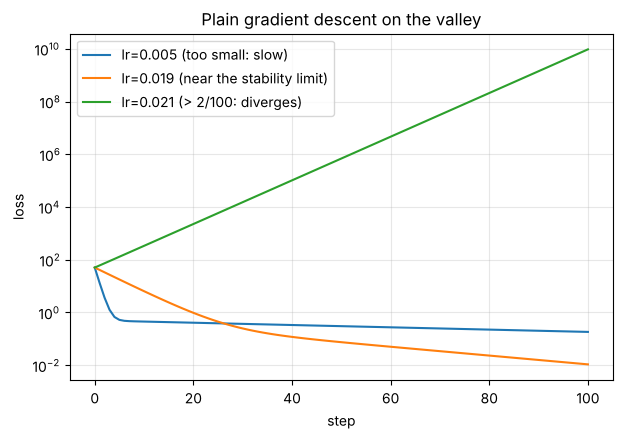

After 200 steps at lr=0.019:  w = [0.     0.0216] (w2 is still far from 0)


In [3]:
fig, ax = plt.subplots()
for lr, label in [(0.005, "lr=0.005 (too small: slow)"),
                  (0.019, "lr=0.019 (near the stability limit)"),
                  (0.021, "lr=0.021 (> 2/100: diverges)")]:
    p = run_gd(lr, steps=100)
    ax.semilogy([loss(w) + 1e-30 for w in p], label=label)
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.set_title("Plain gradient descent on the valley")
ax.legend(); plt.show()

p = run_gd(0.019, steps=200)
print("After 200 steps at lr=0.019:  w =", p[-1], "(w2 is still far from 0)")

### 1b. Trajectories: GD vs momentum vs Adam vs preconditioned (Newton)

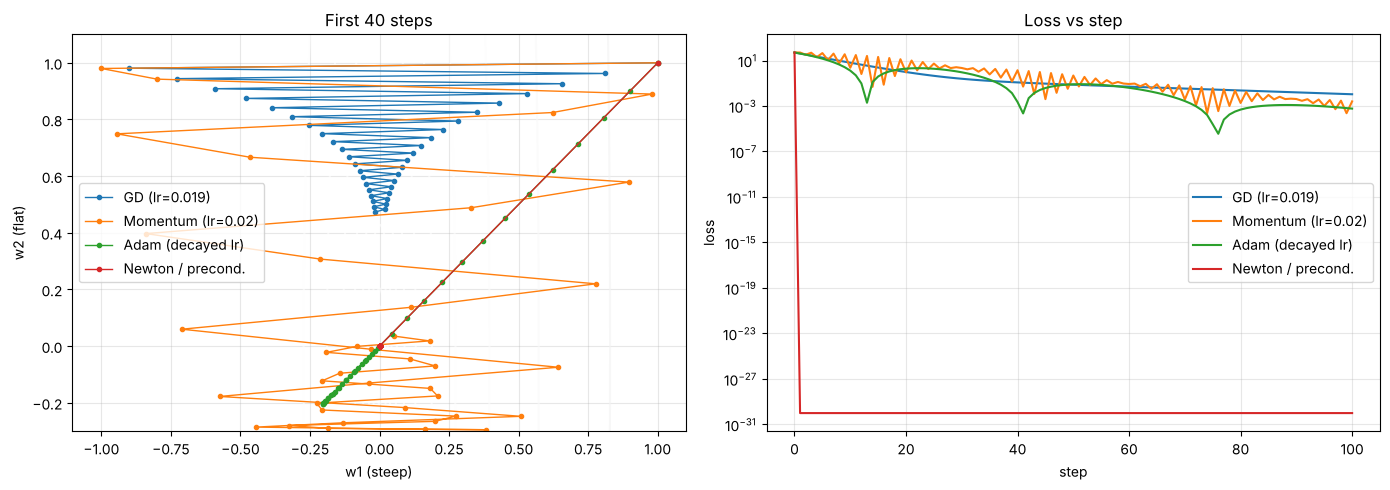

GD (lr=0.019)          final loss = 1.078e-02
Momentum (lr=0.02)     final loss = 2.542e-03
Adam (decayed lr)      final loss = 5.889e-04
Newton / precond.      final loss = 0.000e+00


In [4]:
paths = {
    "GD (lr=0.019)":        run_gd(0.019, 100),
    "Momentum (lr=0.02)":   run_momentum(0.02, 0.9, 100),
    "Adam (decayed lr)":    run_adam(0.1, steps=100),
    "Newton / precond.":    run_newton(100),
}

g1, g2 = np.meshgrid(np.linspace(-0.3, 1.1, 300), np.linspace(-0.3, 1.1, 300))
Z = 0.5 * (H[0] * g1**2 + H[1] * g2**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].contour(g1, g2, Z, levels=np.logspace(-2, 2.5, 15), cmap="Greys", alpha=0.6)
for name, p in paths.items():
    axes[0].plot(p[:40, 0], p[:40, 1], "o-", ms=3, lw=1, label=name)
axes[0].set_xlabel("w1 (steep)"); axes[0].set_ylabel("w2 (flat)")
axes[0].set_title("First 40 steps"); axes[0].legend()

for name, p in paths.items():
    axes[1].semilogy([loss(w) + 1e-30 for w in p], label=name)
axes[1].set_xlabel("step"); axes[1].set_ylabel("loss"); axes[1].set_title("Loss vs step")
axes[1].legend(); plt.tight_layout(); plt.show()

for name, p in paths.items():
    print(f"{name:22s} final loss = {loss(p[-1]):.3e}")

**Reading the plots:** plain GD bounces across the steep `w1` direction while crawling along `w2`. Momentum damps the bouncing and speeds up the flat direction. Adam rescales each coordinate by its own gradient magnitude, so the 100x curvature gap mostly stops mattering. Newton/preconditioning removes the mismatch entirely (one step here, since the loss is quadratic).

## Part 2: The most common cause in practice is unscaled inputs

Linear regression with one well-scaled feature and one feature with a large scale and offset. The Hessian is `X^T X / n`, so feature scale feeds directly into the condition number. **Standardizing inputs** is the cheapest fix.

raw inputs:          condition number =    7214656.5, max safe lr = 7.14e-06
standardized inputs: condition number =          1.0, max safe lr = 1.79e+00


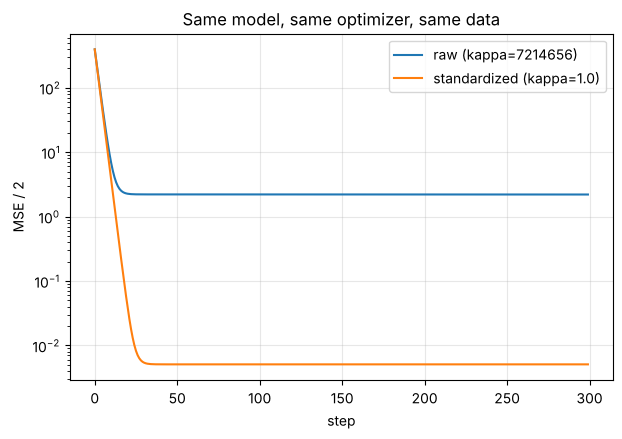

In [5]:
rng = np.random.default_rng(0)
n = 500
x1 = rng.normal(0, 1, n)
x2 = rng.normal(500, 100, n)                      # large mean and scale
y = 3 + 2 * x1 + 0.05 * x2 + rng.normal(0, 0.1, n)

X_raw = np.c_[np.ones(n), x1, x2]
X_std = np.c_[np.ones(n), (x1 - x1.mean()) / x1.std(), (x2 - x2.mean()) / x2.std()]

def fit_gd(X, y, steps=300):
    Hm = X.T @ X / len(X)
    lam = np.linalg.eigvalsh(Hm)
    lr = 0.9 * 2 / lam.max()                      # largest safe learning rate
    w = np.zeros(X.shape[1]); hist = []
    for _ in range(steps):
        r = X @ w - y
        hist.append(0.5 * np.mean(r**2))
        w -= lr * (X.T @ r) / len(X)
    return np.array(hist), lam.max() / lam.min(), lr

h_raw, k_raw, lr_raw = fit_gd(X_raw, y)
h_std, k_std, lr_std = fit_gd(X_std, y)
print(f"raw inputs:          condition number = {k_raw:12.1f}, max safe lr = {lr_raw:.2e}")
print(f"standardized inputs: condition number = {k_std:12.1f}, max safe lr = {lr_std:.2e}")

plt.semilogy(h_raw, label=f"raw (kappa={k_raw:.0f})")
plt.semilogy(h_std, label=f"standardized (kappa={k_std:.1f})")
plt.xlabel("step"); plt.ylabel("MSE / 2"); plt.title("Same model, same optimizer, same data"); plt.legend(); plt.show()

## Part 3: Saturation plateau (vanishing gradient)

One sigmoid neuron, target `y = 1`, input `x = 1`, bad init `w = -6`. The prediction is confidently wrong, yet:

- **MSE** gradient: `2 (s - y) * s (1 - s) * x`. The `s(1-s)` factor is about 0.0025 at `w = -6`, so the gradient is tiny.
- **Cross-entropy (BCE)** gradient: `(s - y) * x`. The `s(1-s)` factor cancels, so the gradient is large exactly when the model is wrong.

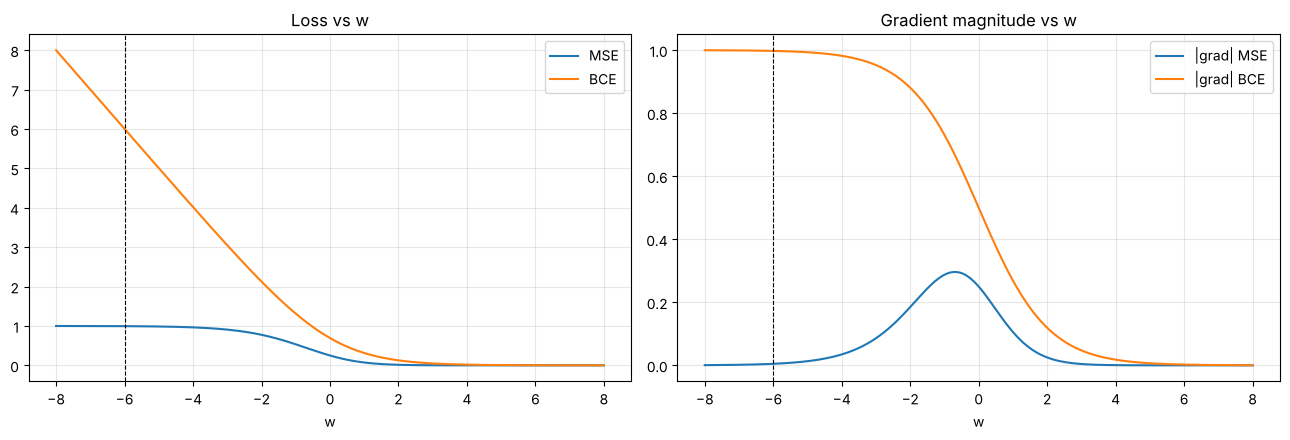

At w=-6: MSE loss=0.995, |grad|=0.00492
At w=-6: BCE loss=6.002, |grad|=0.99753


In [6]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
x, y = 1.0, 1.0

ws = np.linspace(-8, 8, 400)
s = sigmoid(ws * x)
mse   = (s - y) ** 2
bce   = -(y * np.log(s) + (1 - y) * np.log(1 - s + 1e-12))
g_mse = 2 * (s - y) * s * (1 - s) * x
g_bce = (s - y) * x

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ws, mse, label="MSE"); axes[0].plot(ws, bce, label="BCE")
axes[0].axvline(-6, ls="--", c="k", lw=0.8); axes[0].set_title("Loss vs w"); axes[0].set_xlabel("w"); axes[0].legend()
axes[1].plot(ws, np.abs(g_mse), label="|grad| MSE"); axes[1].plot(ws, np.abs(g_bce), label="|grad| BCE")
axes[1].axvline(-6, ls="--", c="k", lw=0.8); axes[1].set_title("Gradient magnitude vs w"); axes[1].set_xlabel("w"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"At w=-6: MSE loss={((sigmoid(-6)-1)**2):.3f}, |grad|={abs(2*(sigmoid(-6)-1)*sigmoid(-6)*(1-sigmoid(-6))):.5f}")
print(f"At w=-6: BCE loss={-np.log(sigmoid(-6)):.3f}, |grad|={abs(sigmoid(-6)-1):.5f}")

Steps to reach prediction > 0.9 from w=-6 (lr=1.0):
  MSE + sigmoid: 249
  BCE + sigmoid: 17


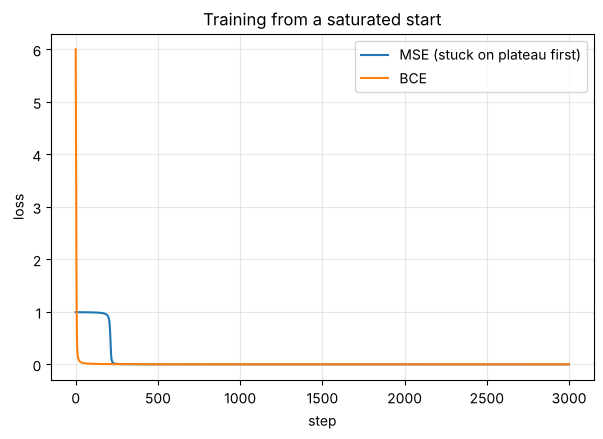

In [7]:
def train_neuron(kind, lr=1.0, steps=3000, w=-6.0):
    losses = []
    for _ in range(steps):
        s = sigmoid(w * x)
        if kind == "mse":
            losses.append((s - y) ** 2); g = 2 * (s - y) * s * (1 - s) * x
        else:
            losses.append(-np.log(s));   g = (s - y) * x
        w -= lr * g
    return np.array(losses), w

l_mse, w_mse = train_neuron("mse")
l_bce, w_bce = train_neuron("bce")

# steps needed to reach prediction > 0.9  (i.e. w > ln 9 ~= 2.2)
def steps_to_converge(kind, lr=1.0, w=-6.0, cap=200000):
    for t in range(cap):
        if sigmoid(w * x) > 0.9: return t
        s = sigmoid(w * x)
        g = 2 * (s - y) * s * (1 - s) * x if kind == "mse" else (s - y) * x
        w -= lr * g
    return None

print("Steps to reach prediction > 0.9 from w=-6 (lr=1.0):")
print("  MSE + sigmoid:", steps_to_converge("mse"))
print("  BCE + sigmoid:", steps_to_converge("bce"))

plt.plot(l_mse, label="MSE (stuck on plateau first)")
plt.plot(l_bce, label="BCE")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training from a saturated start"); plt.legend(); plt.show()

## Part 4: Vanishing gradients in a deep network

A 10-layer MLP with random data. We measure the gradient norm of each layer's weight matrix at initialization. The sigmoid derivative is at most 0.25, so a sigmoid stack with a standard (Xavier) init shrinks gradients layer after layer, which is the classic vanishing gradient (expect a layer-1/layer-10 ratio far below 1e-3). A large N(0,1) init saturates the units instead; the big weights partly offset the shrinkage on the backward pass, so the damage shows up as small, erratic gradients rather than a clean exponential decay. ReLU with He init keeps the gradient scale roughly stable across depth.

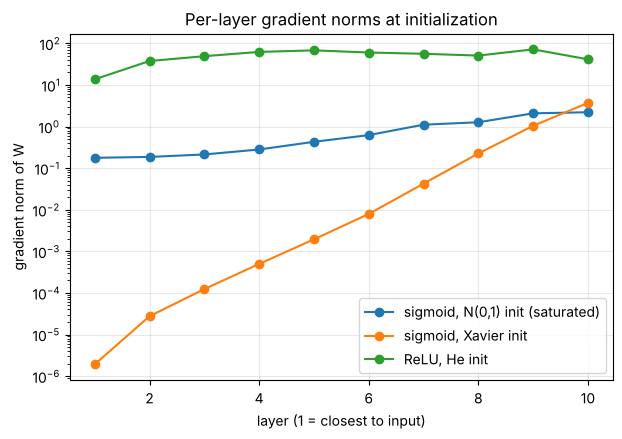

sigmoid, N(0,1) init (saturated)     layer-1 |grad| = 1.77e-01, layer-10 |grad| = 2.21e+00, ratio layer1/layer10 = 8.04e-02
sigmoid, Xavier init                 layer-1 |grad| = 1.92e-06, layer-10 |grad| = 3.70e+00, ratio layer1/layer10 = 5.18e-07
ReLU, He init                        layer-1 |grad| = 1.37e+01, layer-10 |grad| = 4.13e+01, ratio layer1/layer10 = 3.31e-01


In [8]:
def layer_grad_norms(act, std, depth=10, width=64, n=256, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, width)); Y = rng.normal(size=(n, width))
    Ws = [rng.normal(0, std, (width, width)) for _ in range(depth)]
    a, cache = X, []
    for W in Ws:
        z = a @ W
        if act == "sigmoid":
            out = 1 / (1 + np.exp(-z)); d = out * (1 - out)
        else:
            out = np.maximum(z, 0);     d = (z > 0).astype(float)
        cache.append((a, d)); a = out
    delta = (a - Y) / n                           # dL/d(output) for L = 0.5 * sum((a-Y)^2) / n
    norms = []
    for i in reversed(range(len(Ws))):
        a_in, d = cache[i]
        dz = delta * d
        norms.append(np.linalg.norm(a_in.T @ dz))
        delta = dz @ Ws[i].T
    return norms[::-1]

width = 64
configs = {
    "sigmoid, N(0,1) init (saturated)":  ("sigmoid", 1.0),
    "sigmoid, Xavier init":              ("sigmoid", np.sqrt(1 / width)),
    "ReLU, He init":                     ("relu",    np.sqrt(2 / width)),
}
for name, (act, std) in configs.items():
    plt.semilogy(range(1, 11), layer_grad_norms(act, std), "o-", label=name)
plt.xlabel("layer (1 = closest to input)"); plt.ylabel("gradient norm of W")
plt.title("Per-layer gradient norms at initialization"); plt.legend(); plt.show()

for name, (act, std) in configs.items():
    g = layer_grad_norms(act, std)
    print(f"{name:36s} layer-1 |grad| = {g[0]:.2e}, layer-10 |grad| = {g[-1]:.2e}, ratio layer1/layer10 = {g[0]/g[-1]:.2e}")

## Summary of fixes

| Pathology | Symptom | Fix | Why it works |
|---|---|---|---|
| Ill-conditioning | Oscillation across the valley, slow crawl along it | Adam / RMSProp | Per-parameter step size |
| | | Momentum | Damps oscillation, accelerates along flat directions |
| | | Standardize inputs, BatchNorm/LayerNorm | Removes scale mismatch that inflates the condition number |
| | | Preconditioned / second-order (K-FAC, Shampoo) | Corrects for curvature directly |
| Saturation plateau | High loss, near-zero gradient | Cross-entropy with sigmoid/softmax | Activation derivative cancels in the gradient |
| | | ReLU / GELU | Gradient does not vanish for positive inputs |
| | | He / Xavier init | Keeps pre-activations out of the saturated range |
| | | Residual connections | Gradient path that bypasses saturated layers |

**Things to try next:** change the condition number in Part 1, swap in `lr` schedules, or add residual connections to Part 4 and watch the layer-1 gradient recover.